In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import roc_curve, auc

In [2]:
CSV_PATH = "biomet_data.csv"

df = pd.read_csv(CSV_PATH, sep="\t",header=None)
df = df.iloc[:, :-1]
print("Original shape:", df.shape)

Original shape: (144, 1000)


In [3]:
data = df.to_numpy(dtype=float).T
print("After transpose:", data.shape)

After transpose: (1000, 144)


In [4]:
user_data = data.reshape(100, 10, 144)
print(user_data.shape)


(100, 10, 144)


In [5]:
enrollment = user_data[:, :5, :]
test = user_data[:, 5:, :]
print("Enrollment:", enrollment.shape)
print("Test:", test.shape)

Enrollment: (100, 5, 144)
Test: (100, 5, 144)


In [6]:
templates = np.mean(enrollment, axis=1)

print(templates.shape)

(100, 144)


In [7]:
def euclidean_distance(x, y):
    return np.linalg.norm(x - y)

# A. Genuine Distribution 

Euclidean genuine scores

In [8]:
genuine_euclidean = []

for user in range(100):

    template = templates[user]

    for sample in test[user]:

        distance = euclidean_distance(
            sample,
            template
        )

        genuine_euclidean.append(distance)

genuine_euclidean = np.array(genuine_euclidean)

print("Genuine Euclidean scores:", len(genuine_euclidean))

Genuine Euclidean scores: 500


Genuine cosine scores

In [9]:
genuine_cosine = []

for user in range(100):

    template = templates[user]

    for sample in test[user]:

        similarity = cosine_similarity(
            sample.reshape(1, -1),
            template.reshape(1, -1)
        )[0, 0]

        genuine_cosine.append(similarity)

genuine_cosine = np.array(genuine_cosine)

print("Genuine cosine scores:", len(genuine_cosine))

Genuine cosine scores: 500


Genuine Distribution

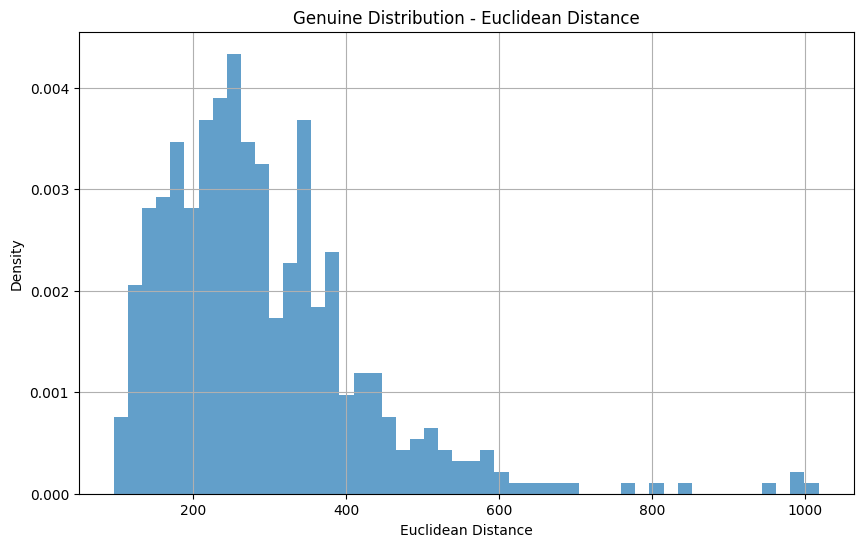

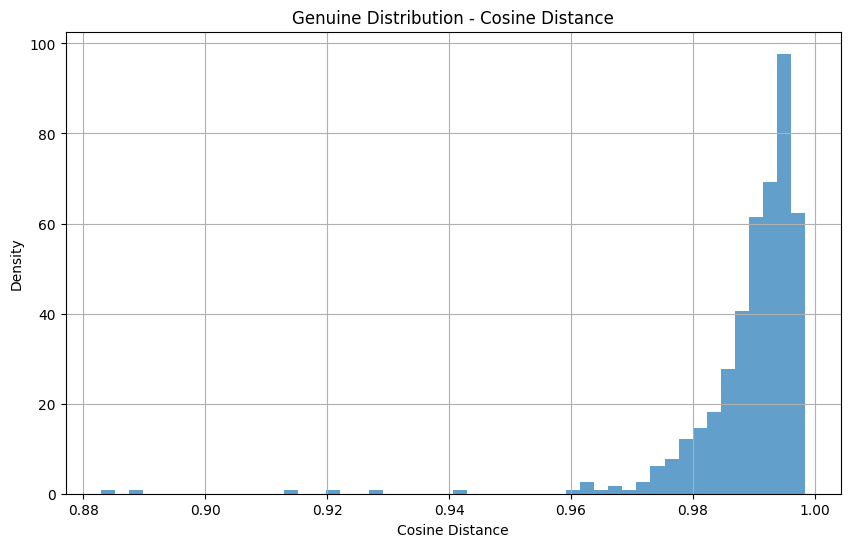

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(
    genuine_euclidean,
    bins=50,
    alpha=0.7,
    density=True
)

plt.xlabel("Euclidean Distance")
plt.ylabel("Density")
plt.title("Genuine Distribution - Euclidean Distance")

plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))

plt.hist(
    genuine_cosine,
    bins=50,
    alpha=0.7,
    density=True
)

plt.xlabel("Cosine Distance")
plt.ylabel("Density")
plt.title("Genuine Distribution - Cosine Distance")

plt.grid(True)
plt.show()



# B. Imposter Distribution 

Calculate imposter Euclidean scores

In [11]:
imposter_euclidean = []

for actual_user in range(100):

    for sample in test[actual_user]:

        for claimed_user in range(100):

            if claimed_user == actual_user:
                continue

            template = templates[claimed_user]

            distance = euclidean_distance(
                sample,
                template
            )

            imposter_euclidean.append(distance)

imposter_euclidean = np.array(imposter_euclidean)

print("Imposter Euclidean scores:",
      len(imposter_euclidean))

Imposter Euclidean scores: 49500


Calculate imposter cosine scores

In [12]:
imposter_cosine = []
for actual_user in range(100):

    for sample in test[actual_user]:

        for claimed_user in range(100):

            if claimed_user == actual_user:
                continue

            template = templates[claimed_user]

            similarity = cosine_similarity(
                sample.reshape(1, -1),
                template.reshape(1, -1)
            )[0, 0]

            imposter_cosine.append(similarity)

imposter_cosine = np.array(imposter_cosine)

print("Imposter cosine scores:",
      len(imposter_cosine))

Imposter cosine scores: 49500


Imposter Distribution

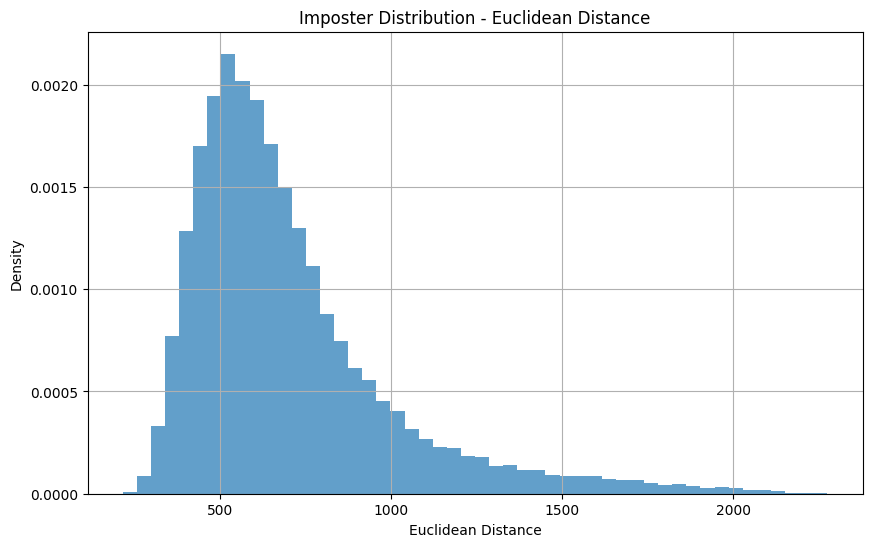

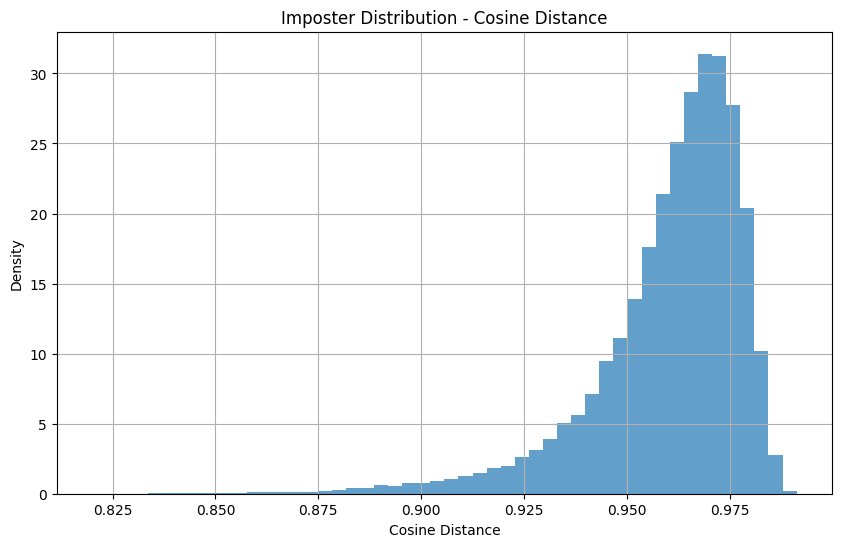

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(
    imposter_euclidean,
    bins=50,
    alpha=0.7,
    density=True
)

plt.xlabel("Euclidean Distance")
plt.ylabel("Density")
plt.title("Imposter Distribution - Euclidean Distance")

plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))

plt.hist(
    imposter_cosine,
    bins=50,
    alpha=0.7,
    density=True
)

plt.xlabel("Cosine Distance")
plt.ylabel("Density")
plt.title("Imposter Distribution - Cosine Distance")

plt.grid(True)
plt.show()

# both together

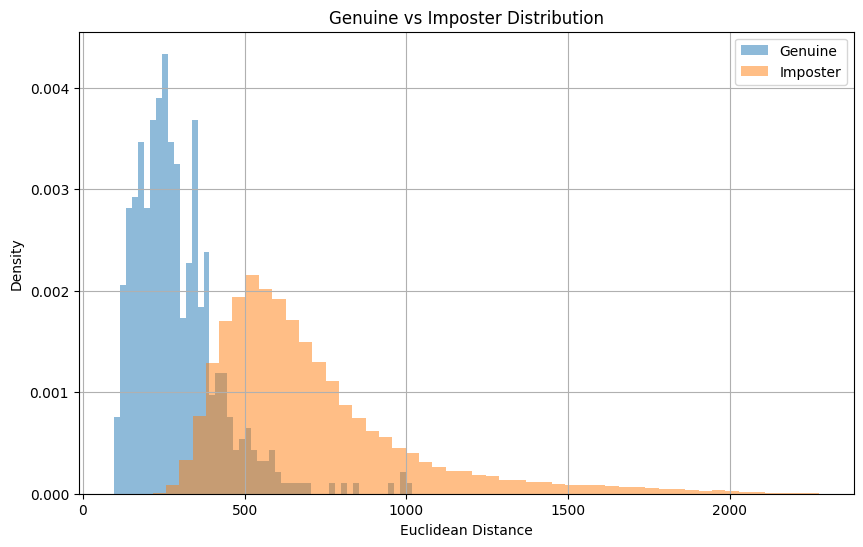

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(
    genuine_euclidean,
    bins=50,
    density=True,
    alpha=0.5,
    label="Genuine"
)

plt.hist(
    imposter_euclidean,
    bins=50,
    density=True,
    alpha=0.5,
    label="Imposter"
)

plt.xlabel("Euclidean Distance")
plt.ylabel("Density")
plt.title("Genuine vs Imposter Distribution")

plt.legend()
plt.grid(True)
plt.show()

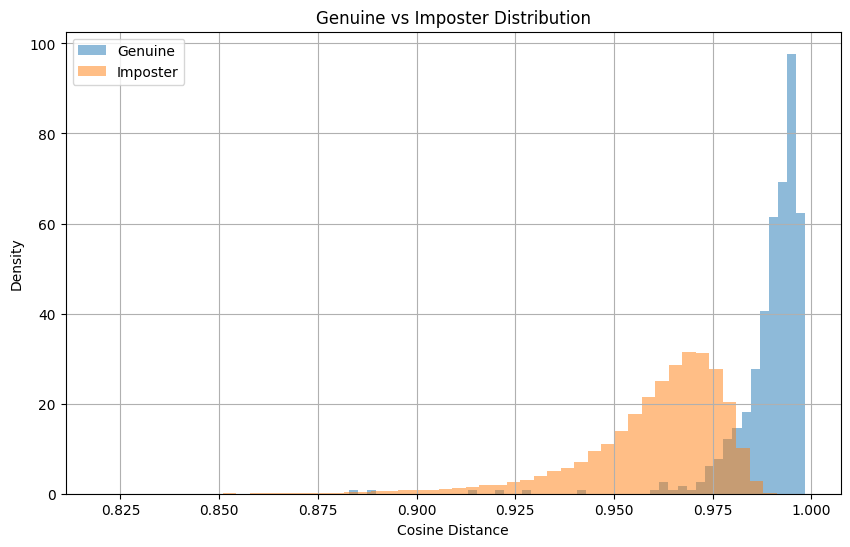

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(
    genuine_cosine,
    bins=50,
    density=True,
    alpha=0.5,
    label="Genuine"
)

plt.hist(
    imposter_cosine,
    bins=50,
    density=True,
    alpha=0.5,
    label="Imposter"
)

plt.xlabel("Cosine Distance")
plt.ylabel("Density")
plt.title("Genuine vs Imposter Distribution")

plt.legend()
plt.grid(True)
plt.show()

# C. FAR Plot 

FAR and FRR code for Euclidean

In [16]:
thresholds_euclidean = np.linspace(
    min(
        genuine_euclidean.min(),
        imposter_euclidean.min()
    ),
    max(
        genuine_euclidean.max(),
        imposter_euclidean.max()
    ),
    500
)

far_euclidean = []
frr_euclidean = []

for threshold in thresholds_euclidean:

    false_accepts = np.sum(
        imposter_euclidean <= threshold
    )

    false_rejects = np.sum(
        genuine_euclidean > threshold
    )

    FAR = false_accepts / len(imposter_euclidean)

    FRR = false_rejects / len(genuine_euclidean)

    far_euclidean.append(FAR)
    frr_euclidean.append(FRR)

far_euclidean = np.array(far_euclidean)
frr_euclidean = np.array(frr_euclidean)

Plot FAR

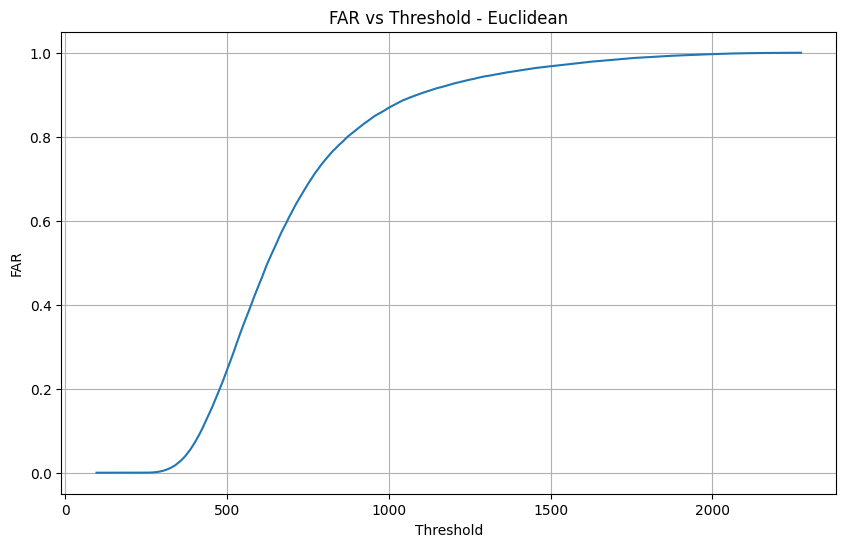

In [17]:
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds_euclidean,
    far_euclidean
)

plt.xlabel("Threshold")
plt.ylabel("FAR")
plt.title("FAR vs Threshold - Euclidean")

plt.grid(True)
plt.show()

Plot FRR

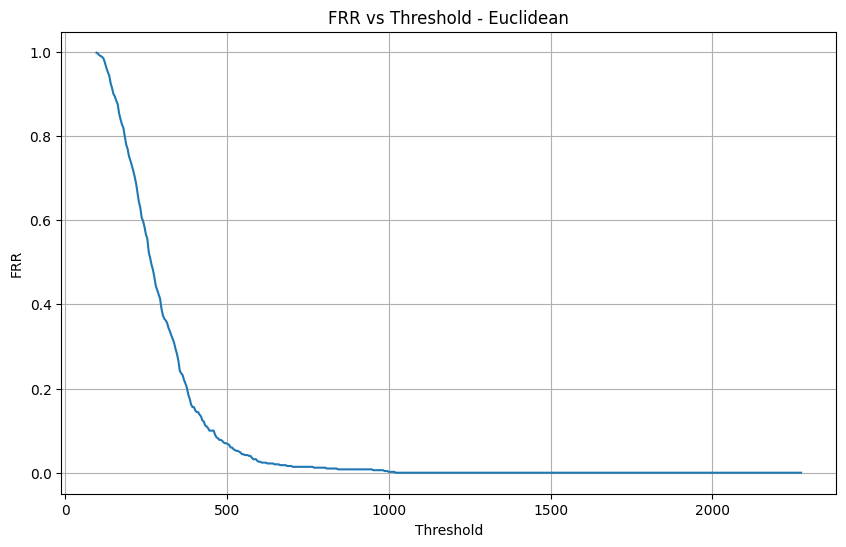

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds_euclidean,
    frr_euclidean
)

plt.xlabel("Threshold")
plt.ylabel("FRR")
plt.title("FRR vs Threshold - Euclidean")

plt.grid(True)
plt.show()

Plot of FAR and FRR

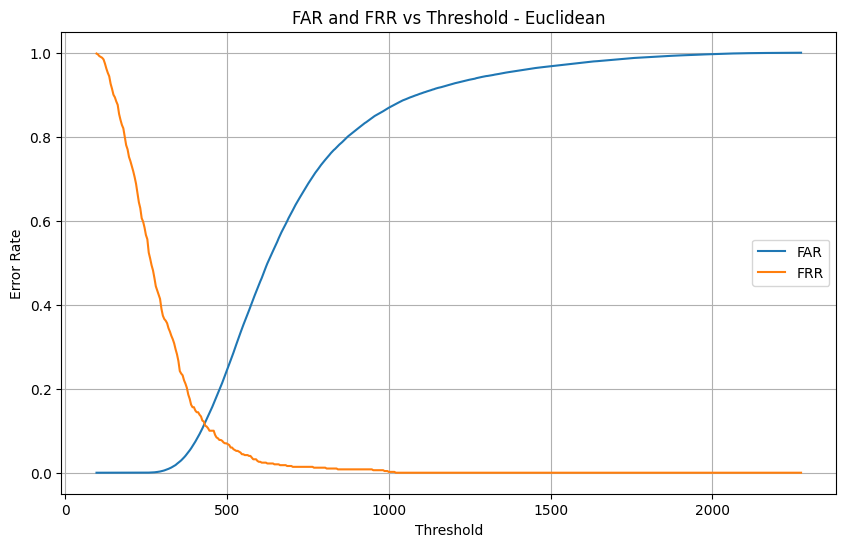

In [19]:
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds_euclidean,
    far_euclidean,
    label="FAR"
)

plt.plot(
    thresholds_euclidean,
    frr_euclidean,
    label="FRR"
)

plt.xlabel("Threshold")
plt.ylabel("Error Rate")
plt.title("FAR and FRR vs Threshold - Euclidean")

plt.legend()
plt.grid(True)
plt.show()

# F. Equal Error Rate and Decidability Index 

EER

In [20]:
eer_index = np.argmin(
    np.abs(far_euclidean - frr_euclidean)
)

eer_euclidean = (
    far_euclidean[eer_index] +
    frr_euclidean[eer_index]
) / 2

eer_threshold_euclidean = (
    thresholds_euclidean[eer_index]
)

print("EER:", eer_euclidean)
print(
    "EER Threshold:",
    eer_threshold_euclidean
)

EER: 0.11588888888888889
EER Threshold: 432.09949599206465


Prepare ROC data

In [21]:
genuine_scores_euclidean = -genuine_euclidean
imposter_scores_euclidean = -imposter_euclidean

scores_euclidean = np.concatenate([
    genuine_scores_euclidean,
    imposter_scores_euclidean
])

labels_euclidean = np.concatenate([
    np.ones(len(genuine_scores_euclidean)),
    np.zeros(len(imposter_scores_euclidean))
])

Calculate ROC

In [22]:
fpr_euc, tpr_euc, roc_thresholds_euc = roc_curve(
    labels_euclidean,
    scores_euclidean
)

auc_euc = auc(
    fpr_euc,
    tpr_euc
)

print("AUC:", auc_euc)

AUC: 0.9495562424242423


plot ROC

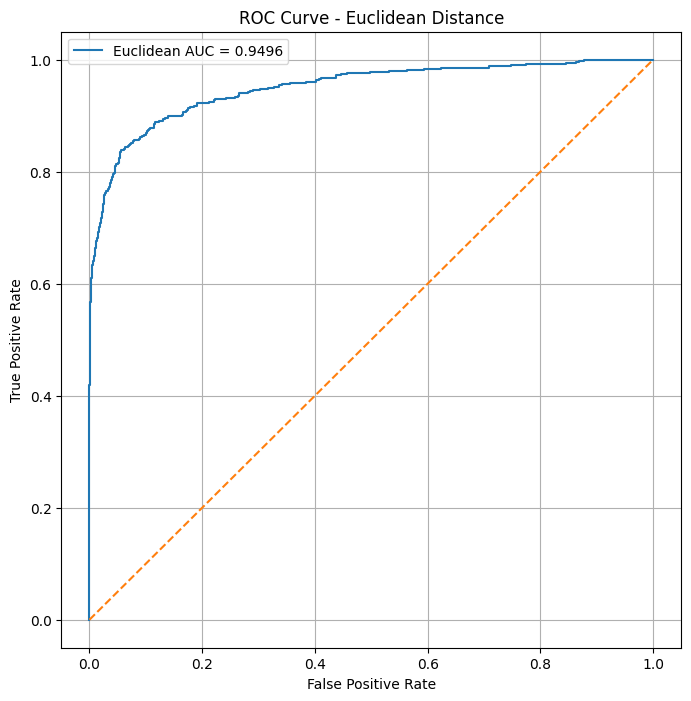

In [23]:
plt.figure(figsize=(8, 8))

plt.plot(
    fpr_euc,
    tpr_euc,
    label=f"Euclidean AUC = {auc_euc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Euclidean Distance")

plt.legend()
plt.grid(True)
plt.show()

ROC of cosine

In [24]:
scores_cosine = np.concatenate([
    genuine_cosine,
    imposter_cosine
])

labels_cosine = np.concatenate([
    np.ones(len(genuine_cosine)),
    np.zeros(len(imposter_cosine))
])

fpr_cos, tpr_cos, roc_thresholds_cos = roc_curve(
    labels_cosine,
    scores_cosine
)

auc_cos = auc(
    fpr_cos,
    tpr_cos
)

print("Cosine AUC:", auc_cos)

Cosine AUC: 0.9689432323232323


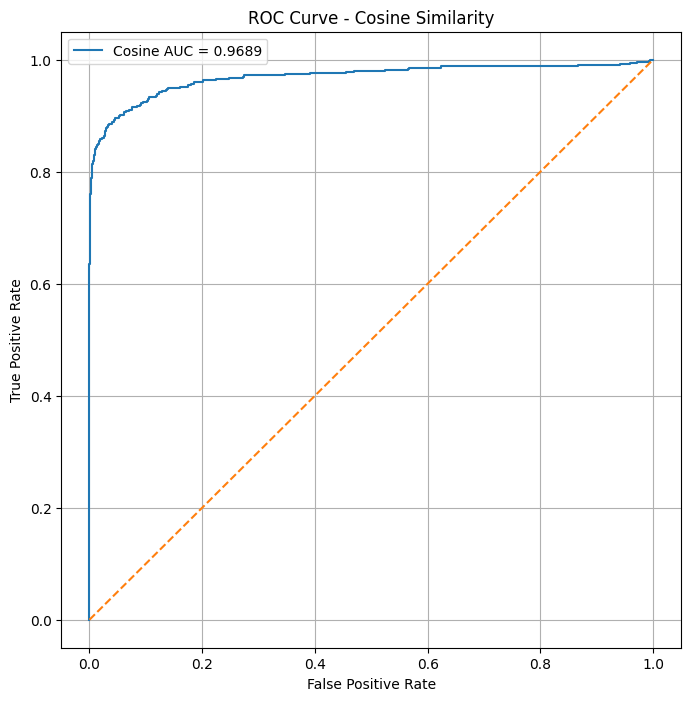

In [25]:
plt.figure(figsize=(8, 8))

plt.plot(
    fpr_cos,
    tpr_cos,
    label=f"Cosine AUC = {auc_cos:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Cosine Similarity")

plt.legend()
plt.grid(True)
plt.show()

### Decidability for Euclidean

In [26]:
mu_g_euc = np.mean(genuine_euclidean)
mu_i_euc = np.mean(imposter_euclidean)

std_g_euc = np.std(genuine_euclidean)
std_i_euc = np.std(imposter_euclidean)

dprime_euc = abs(
    mu_g_euc - mu_i_euc
) / np.sqrt(
    (std_g_euc**2 + std_i_euc**2) / 2
)

print("Euclidean Decidability Index:", dprime_euc)

Euclidean Decidability Index: 1.7622461862707728


### Decidability for Cosine

In [27]:
mu_g_cos = np.mean(genuine_cosine)
mu_i_cos = np.mean(imposter_cosine)

std_g_cos = np.std(genuine_cosine)
std_i_cos = np.std(imposter_cosine)

dprime_cos = abs(
    mu_g_cos - mu_i_cos
) / np.sqrt(
    (std_g_cos**2 + std_i_cos**2) / 2
)

print("Cosine Decidability Index:", dprime_cos)

Cosine Decidability Index: 1.9259344481978715
